# Phase 2 & 4: Segmentation (U-Net)

A U-Net with a pretrained ResNet34 encoder draws the outline (mask) of every lesion. With `MULTI_TASK = True` it also classifies the scan as normal / benign / malignant.

| `MULTI_TASK` | Phase | Model outputs | Saved to |
| :----------: | ----- | ------------- | -------- |
| `False` | Phase 2 | Lesion mask | `outputs/unet/` |
| `True` | Phase 4 | Lesion mask **and** normal / benign / malignant | `outputs/unet_multitask/` |

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output** (everything the Streamlit app needs):

| File | What it contains |
| ---- | ---------------- |
| `model_fold0.pt` … `model_fold4.pt` | The 5 trained models (v3: one per fold); the app averages them |
| `config.json` | Architecture, image size, normalisation, thresholds, mask smoothing / cleanup, model files and training settings |
| `history.csv` | Loss, Dice and accuracy for every epoch of every fold |
| `metrics.json` | Test results (v3), with 95% confidence ranges |
| `metrics_by_version.csv` | v1, v2 and v3 test results side by side, on the same test images |
| `single_vs_ensemble.csv` | Each of the 5 models on its own vs their average |
| `test_predictions.csv` | Dice, IoU, lesion area and class probabilities for every test image |
| `oof_predictions.csv` | Out-of-fold class probabilities for every cross-validation image (used to tune the threshold) |
| `masks/` | Predicted mask (v3 ensemble) for every test image, at the original size (used by `04_measure`) |
| `training_curves.png`, `threshold_tuning.png`, `dice_distribution.png`, `confusion_matrix.png`, `prediction_examples.png`, `worst_predictions.png` | Result plots |

**Before the first run:** install the U-Net library with `.env/bin/pip install segmentation-models-pytorch`.

---

### v2 changes (kept)

| Change | Why |
| ------ | --- |
| **Smooth masks:** enlarge the probability map to the original size, then threshold | v1's staircase edges made outlines look rougher and less round than the real lesions |
| **Mask cleanup:** fill holes, drop regions smaller than `MIN_REGION_PCT` % of the image | Removed 6 false lesions in v2 without losing real ones |
| **Malignant threshold** and **95% confidence ranges** | Catch more cancers; see how much of a change is luck |
| *(Normal gate: tested in v2 and removed; it hid a real lesion and none of the false ones)* | |

### v3 changes

| Change | Why |
| ------ | --- |
| **New data split** from `00_clean_data` v3 (look-alike duplicates removed, test set frozen to 102 of the v1 test images) | Conflicting duplicates and train/test look-alikes |
| **5-fold cross-validation + ensemble** (5 models; the test prediction averages their masks and class probabilities) | In v2 the validation set was also used for early stopping, so it flattered the model (93.5% malignant recall on validation vs 70% on test). The ensemble also improved every score in `02_model_classifier` |
| **Malignant threshold tuned on the out-of-fold predictions** (567 images) | Unbiased, and about 170 cancers instead of 31 |
| **Image size 384 instead of 256** | At 256 the predicted malignant outlines were too smooth: only 3 of 9 irregular lesions were labelled irregular in v2 |
| **v1, v2 and v3 scored on the same 102 test images** | Fair comparison |

v1 and v2 are archived in `outputs/archive/` and git tags `v1-baseline`, `v2-postprocessing`.

## 1. Imports

In [93]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from PIL import Image, ImageOps
from scipy import ndimage                     # hole filling and region sizes for mask cleanup
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

## 2. Settings

In [94]:
DATA_DIR = Path('data')
ARCHIVE_DIR = Path('outputs/archive')           # v1 and v2 results, used for the comparison

MULTI_TASK = True    # False = Phase 2 (mask only), True = Phase 4 (mask + normal / benign / malignant)

OUTPUT_DIR = Path('outputs/unet_multitask' if MULTI_TASK else 'outputs/unet')
MASK_DIR = OUTPUT_DIR / 'masks'                 # predicted test masks go here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']     # class numbers 0, 1, 2
ENCODER = 'resnet34'          # pretrained backbone of the U-Net
IMAGE_SIZE = 384              # v3: was 256; every scan is padded and resized to this size (must be divisible by 32)
BATCH_SIZE = 8
EPOCHS = 40                   # maximum per model; training can stop earlier
LEARNING_RATE = 1e-4
PATIENCE = 8                  # stop if validation loss hasn't improved for this many epochs
CLASS_LOSS_WEIGHT = 0.5       # how much the classification loss counts compared to the mask loss
MASK_THRESHOLD = 0.5          # pixels with lesion probability above this are part of the mask
MIN_LESION_PIXELS = 50        # same as 00_clean_data: smaller regions are noise
RANDOM_STATE = 42

TRAIN = True                    # v3: True = train the 5 fold models, False = reuse the saved ones
TARGET_MALIGNANT_RECALL = 0.90  # v2: the malignant threshold is tuned to reach this recall
SMOOTH_MASKS = True             # v2: enlarge the probability map to full size before thresholding (smooth edges)
CLEAN_MASKS = True              # v2: fill holes and drop small regions in predicted masks
MIN_REGION_PCT = 0.2            # v2: regions smaller than this % of the image are dropped (smallest real lesion is ~0.3%)
N_BOOTSTRAP = 1000              # v2: resamples used for the 95% confidence ranges

IMAGENET_MEAN = [0.485, 0.456, 0.406]           # the pretrained encoder expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]


def set_seed(seed):
    """Same random numbers every run (v3: called once per fold, with a different seed per fold)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device, '| Multi-task:', MULTI_TASK, '| Image size:', IMAGE_SIZE,
      '| Train new models:', TRAIN, '| Saving to:', OUTPUT_DIR)

Using device: mps | Multi-task: True | Image size: 384 | Train new models: True | Saving to: outputs/unet_multitask


## 3. Load the manifest

**v3:** 102 **test** images (never used for training or tuning) and **5 cross-validation folds** (the other 567 images).

In [95]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

pool_df = df[df['fold'] >= 0].reset_index(drop=True)           # v3: the 5 cross-validation folds
test_df = df[df['split'] == 'test'].reset_index(drop=True)
N_FOLDS = pool_df['fold'].nunique()

print(f'Cross-validation: {len(pool_df)} images in {N_FOLDS} folds  |  Test: {len(test_df)}')
pd.crosstab(pool_df['label'], pool_df['fold'], margins=True)

Cross-validation: 567 images in 5 folds  |  Test: 102


fold,0,1,2,3,4,All
label,,,,,,
benign,61,61,61,62,62,307
malignant,34,34,34,34,34,170
normal,18,18,18,18,18,90
All,113,113,113,114,114,567


## 4. Images, masks and helper functions

Image and mask go through the **same** padding and resizing, so they stay perfectly aligned:
- **Image:** grayscale, then black borders to make it square, then resize (smooth resizing).
- **Mask:** all of the image's masks merged into one, then the same borders and resize, using *nearest-neighbour* resizing so pixels stay exactly 0 or 1.

Going back to the original image size, so lesions can be measured in real image pixels:
- `unpad_mask`: cuts the borders off a **yes/no** mask and enlarges it (v1 method, staircase edges).
- `unpad_probs` (v2): cuts the borders off the **probability map** and enlarges it smoothly; thresholding afterwards gives smooth edges.

In [96]:
def pad_to_square(image, is_mask=False, size=IMAGE_SIZE):
    """Fit an image into size x size with black borders (no stretching)."""
    method = Image.NEAREST if is_mask else Image.BICUBIC      # nearest keeps mask pixels exactly 0 or 255
    return ImageOps.pad(image, (size, size), method=method, color=0)


def load_mask(mask_paths):
    """Merge all masks of an image into one PIL image (255 = lesion, 0 = background)."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)


def crop_box(width, height, size=IMAGE_SIZE):
    """Where the original image sits inside the padded square: (left, top, new_width, new_height)."""
    scale = size / max(width, height)
    new_width, new_height = round(width * scale), round(height * scale)              # image size inside the square
    left, top = round((size - new_width) / 2), round((size - new_height) / 2)        # where the image starts
    return left, top, new_width, new_height


def unpad_mask(mask, width, height, size=IMAGE_SIZE):
    """Undo pad_to_square: cut off the borders and resize a True/False mask back to width x height."""
    left, top, new_width, new_height = crop_box(width, height, size)
    cropped = mask[top:top + new_height, left:left + new_width]
    resized = Image.fromarray(cropped.astype(np.uint8) * 255).resize((width, height), Image.NEAREST)
    return np.array(resized) > 127


def unpad_probs(probs, width, height, size=IMAGE_SIZE):
    """v2: undo pad_to_square for a probability map: cut off the borders and resize smoothly back to width x height."""
    left, top, new_width, new_height = crop_box(width, height, size)
    cropped = probs[top:top + new_height, left:left + new_width].astype(np.float32)
    return np.array(Image.fromarray(cropped).resize((width, height), Image.BILINEAR))


def clean_mask(mask, min_region_pct=MIN_REGION_PCT, min_pixels=MIN_LESION_PIXELS):
    """v2: fill holes inside lesions, then drop regions smaller than min_region_pct % of the image."""
    filled = ndimage.binary_fill_holes(mask)
    labelled, n_regions = ndimage.label(filled, structure=np.ones((3, 3)))     # number each separate region
    sizes = ndimage.sum(filled, labelled, range(1, n_regions + 1))             # pixels in each region
    min_size = max(min_pixels, mask.size * min_region_pct / 100)
    keep = [number for number, size in enumerate(sizes, start=1) if size >= min_size]
    return np.isin(labelled, keep)


def final_mask(probs, width, height):
    """v2 mask at the original size: smooth enlargement (if SMOOTH_MASKS), threshold, then cleanup (if CLEAN_MASKS)."""
    if SMOOTH_MASKS:
        mask = unpad_probs(probs, width, height) > MASK_THRESHOLD
    else:
        mask = unpad_mask(probs > MASK_THRESHOLD, width, height)
    return clean_mask(mask) if CLEAN_MASKS else mask


def dice_score(pred, truth):
    """Overlap of two True/False masks: 1 = identical, 0 = no overlap."""
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else float(2 * (pred & truth).sum() / total)


def iou_score(pred, truth):
    """Intersection over union of two True/False masks: 1 = identical, 0 = no overlap."""
    union = (pred | truth).sum()
    return 1.0 if union == 0 else float((pred & truth).sum() / union)

In [97]:
# Check: padding a real mask and undoing it should give back (almost) the same mask
row = df[df['label'] == 'malignant'].iloc[0]
original = np.array(load_mask(row['mask_paths'])) > 127
padded = np.array(pad_to_square(load_mask(row['mask_paths']), is_mask=True)) > 127
round_trip = unpad_mask(padded, row['width'], row['height'])
print(f'Dice after pad + unpad at {IMAGE_SIZE} px: {dice_score(round_trip, original):.3f}  (should be close to 1)')

Dice after pad + unpad at 384 px: 0.997  (should be close to 1)


### Augmentation and dataset

Training images get small random flips, rotations, shifts and zooms. Each change is applied to the image **and** its mask together, so the outline still matches. Brightness and contrast changes only affect the image. There are no vertical flips, because the skin is always at the top.

In [98]:
train_augment = v2.Compose([
    v2.RandomHorizontalFlip(),                                              # left-right flip only
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    v2.ColorJitter(brightness=0.2, contrast=0.2),                           # image only, the mask is untouched
])

MEAN = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def to_model_input(image):
    """1-channel uint8 image tensor (1, H, W) -> normalised 3-channel float tensor (3, H, W)."""
    x = torch.as_tensor(image).float().div(255).repeat(3, 1, 1)   # 0..255 -> 0..1, then copy to 3 channels
    return (x - MEAN) / STD


class ScanMaskDataset(Dataset):
    """Gives (image tensor, mask tensor, class number) for each row of the manifest."""

    def __init__(self, frame, augment=None):
        self.frame = frame.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']).convert('L'))
        mask = pad_to_square(load_mask(row['mask_paths']), is_mask=True)

        image = tv_tensors.Image(torch.from_numpy(np.array(image)).unsqueeze(0))                   # (1, H, W)
        mask = tv_tensors.Mask(torch.from_numpy(np.array(mask) > 127).unsqueeze(0).to(torch.uint8))
        if self.augment:
            image, mask = self.augment(image, mask)       # same random change for image and mask

        return to_model_input(image), torch.as_tensor(mask).float(), row['target']


def make_loader(frame, train=False):
    """v3: a DataLoader for any part of the data. Training loaders shuffle and augment; others keep the order."""
    return DataLoader(ScanMaskDataset(frame, train_augment if train else None), batch_size=BATCH_SIZE, shuffle=train)

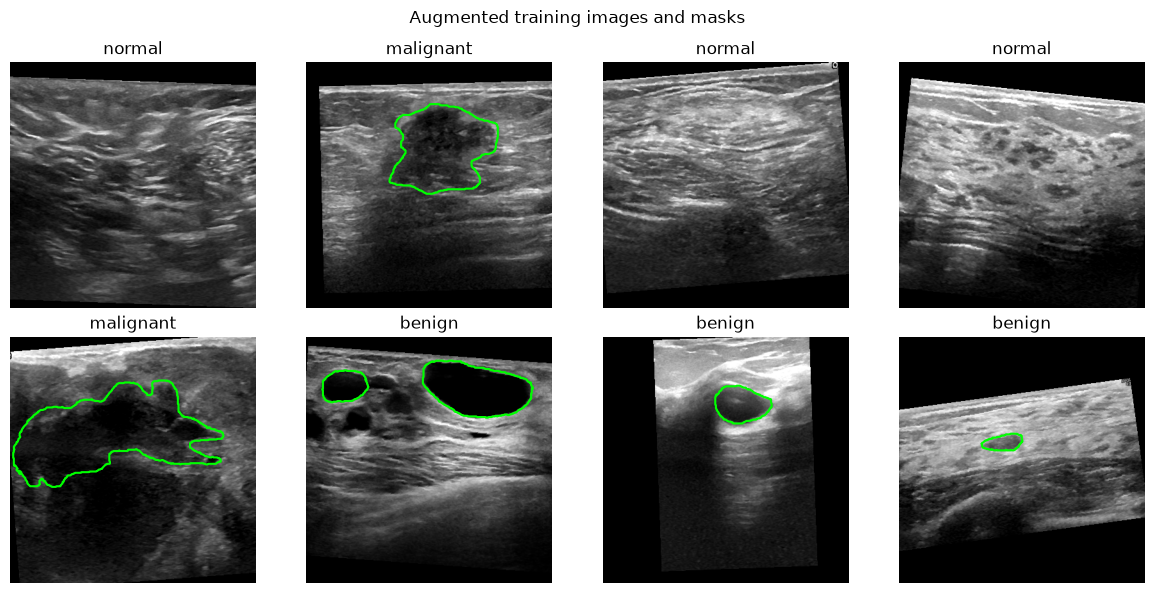

In [99]:
# Look at one batch of augmented training images with their masks (green outline)
images, masks, targets = next(iter(make_loader(pool_df, train=True)))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, mask, target in zip(axes.flat, images, masks, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation
    if mask.any():
        ax.contour(mask[0].numpy(), levels=[0.5], colors='lime', linewidths=1.5)
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images and masks')
plt.tight_layout()
plt.show()

## 5. Model and loss

**U-Net:** the *encoder* (a ResNet34 pretrained on ImageNet) shrinks the image step by step into features. The *decoder* grows those features back to full size to draw the mask. *Skip connections* pass details from each encoder step to the decoder, which keeps the edges sharp.

With `MULTI_TASK = True`, a small **classification head** also reads the encoder's deepest features and predicts normal / benign / malignant.

**Loss:** Dice loss + binary cross-entropy for the mask, plus `CLASS_LOSS_WEIGHT` x weighted cross-entropy for the class. **v3:** each fold model starts from fresh ImageNet weights and gets its own class weights.

In [100]:
def build_model(pretrained=True):
    """U-Net with a ResNet34 encoder (ImageNet weights unless pretrained=False), plus a classification head if multi-task."""
    return smp.Unet(
        encoder_name=ENCODER,
        encoder_weights='imagenet' if pretrained else None,
        in_channels=3,
        classes=1,                           # one output channel: lesion vs background
        aux_params={'classes': len(CLASSES), 'dropout': 0.2} if MULTI_TASK else None,   # classification head
    ).to(device)


def forward(model, images):
    """Run a model. Always returns (mask_logits, class_logits); class_logits is None without multi-task."""
    output = model(images)
    return output if MULTI_TASK else (output, None)


def dice_loss(mask_logits, masks, smooth=1.0):
    """1 - Dice overlap between predicted probabilities and true masks (0 = perfect)."""
    probs = torch.sigmoid(mask_logits)
    intersection = (probs * masks).sum()
    return 1 - (2 * intersection + smooth) / (probs.sum() + masks.sum() + smooth)


bce_loss = nn.BCEWithLogitsLoss()


def class_weights_for(frame):
    """Rarer classes get a bigger weight in the classification loss."""
    counts = frame['target'].value_counts().reindex(range(len(CLASSES)), fill_value=0)
    return torch.tensor(len(frame) / (len(CLASSES) * counts.values), dtype=torch.float32)


def total_loss(mask_logits, class_logits, masks, targets, class_loss_fn):
    """Mask loss, plus the weighted classification loss when multi-task."""
    loss = dice_loss(mask_logits, masks) + bce_loss(mask_logits, masks)
    if MULTI_TASK:
        loss = loss + CLASS_LOSS_WEIGHT * class_loss_fn(class_logits, targets)
    return loss

## 6. Train: 5-fold cross-validation (v3)

For each fold `k` (0 to 4), a fresh U-Net trains on the **other 4 folds**, is checked on **fold k** after every epoch, saves its best epoch to `model_fold{k}.pt`, and stops early after `PATIENCE` epochs without improvement.

**This is the longest step of the project:** 5 models at 384 px. Expect roughly 1–3 hours on a Mac. One line is printed per epoch so you can follow the progress.

With `TRAIN = False`, training is skipped and the saved `model_fold*.pt` files and `history.csv` are reused.

In [101]:
def run_epoch(model, loader, class_loss_fn, optimizer=None):
    """One pass over the data. Trains when an optimizer is given. Returns (loss, dice, accuracy)."""
    train = optimizer is not None
    model.train(train)
    total, overlap, mask_total, correct = 0.0, 0.0, 0.0, 0

    for images, masks, targets in loader:
        images, masks, targets = images.to(device), masks.to(device), targets.to(device)

        with torch.set_grad_enabled(train):                 # only track gradients when training
            mask_logits, class_logits = forward(model, images)
            loss = total_loss(mask_logits, class_logits, masks, targets, class_loss_fn)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        with torch.no_grad():                               # scores for this batch
            total += loss.item() * len(targets)
            predicted = (torch.sigmoid(mask_logits) > MASK_THRESHOLD).float()
            overlap += (predicted * masks).sum().item()
            mask_total += (predicted.sum() + masks.sum()).item()
            if MULTI_TASK:
                correct += (class_logits.argmax(dim=1) == targets).sum().item()

    n = len(loader.dataset)
    return total / n, 2 * overlap / max(mask_total, 1), correct / n


def train_fold(fold):
    """v3: train one model on the other folds, with early stopping on this fold. Saves model_fold{fold}.pt."""
    set_seed(RANDOM_STATE + fold)
    train_part = pool_df[pool_df['fold'] != fold]
    val_part = pool_df[pool_df['fold'] == fold]

    model = build_model()
    class_loss_fn = nn.CrossEntropyLoss(weight=class_weights_for(train_part).to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader, val_loader = make_loader(train_part, train=True), make_loader(val_part)

    history, best_val_loss, best_epoch, epochs_without_improvement = [], float('inf'), 0, 0
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_dice, train_acc = run_epoch(model, train_loader, class_loss_fn, optimizer)
        val_loss, val_dice, val_acc = run_epoch(model, val_loader, class_loss_fn)
        history.append({'fold': fold, 'epoch': epoch, 'train_loss': train_loss, 'train_dice': train_dice,
                        'train_acc': train_acc, 'val_loss': val_loss, 'val_dice': val_dice, 'val_acc': val_acc})
        print(f'Fold {fold} | epoch {epoch:2d} | train loss {train_loss:.3f} dice {train_dice:.3f} '
              f'| val loss {val_loss:.3f} dice {val_dice:.3f}' + (f' acc {val_acc:.3f}' if MULTI_TASK else ''))

        if val_loss < best_val_loss:                         # new best: save this model
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            torch.save(model.state_dict(), OUTPUT_DIR / f'model_fold{fold}.pt')
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    best = history[best_epoch - 1]
    print(f'==> Fold {fold}: best epoch {best_epoch} (val loss {best_val_loss:.3f}, dice {best["val_dice"]:.3f}'
          + (f', acc {best["val_acc"]:.3f})' if MULTI_TASK else ')') + '\n')
    return pd.DataFrame(history), best_epoch

In [102]:
if TRAIN:
    histories, best_epochs = [], []
    for fold in range(N_FOLDS):
        fold_history, best = train_fold(fold)
        histories.append(fold_history)
        best_epochs.append(best)
    history = pd.concat(histories, ignore_index=True)
    history.to_csv(OUTPUT_DIR / 'history.csv', index=False)
    (OUTPUT_DIR / 'model.pt').unlink(missing_ok=True)      # v3: replaced by model_fold*.pt (the v2 model is archived)
else:
    # Reuse the saved fold models, history and settings (nothing is retrained)
    previous_config = json.loads((OUTPUT_DIR / 'config.json').read_text())
    history = pd.read_csv(OUTPUT_DIR / 'history.csv')
    best_epochs = previous_config['best_epochs']
    print(f"Skipping training: reusing the {N_FOLDS} fold models (trained on {previous_config['trained_on']})")

Fold 0 | epoch  1 | train loss 1.982 dice 0.253 | val loss 1.947 dice 0.427 acc 0.735
Fold 0 | epoch  2 | train loss 1.422 dice 0.622 | val loss 1.615 dice 0.582 acc 0.708
Fold 0 | epoch  3 | train loss 1.207 dice 0.640 | val loss 1.249 dice 0.656 acc 0.805
Fold 0 | epoch  4 | train loss 1.039 dice 0.690 | val loss 1.212 dice 0.660 acc 0.761
Fold 0 | epoch  5 | train loss 0.922 dice 0.720 | val loss 1.107 dice 0.650 acc 0.823
Fold 0 | epoch  6 | train loss 0.787 dice 0.737 | val loss 0.937 dice 0.703 acc 0.850
Fold 0 | epoch  7 | train loss 0.747 dice 0.740 | val loss 1.043 dice 0.680 acc 0.841
Fold 0 | epoch  8 | train loss 0.713 dice 0.744 | val loss 1.061 dice 0.675 acc 0.814
Fold 0 | epoch  9 | train loss 0.629 dice 0.760 | val loss 0.842 dice 0.722 acc 0.876
Fold 0 | epoch 10 | train loss 0.564 dice 0.783 | val loss 1.005 dice 0.680 acc 0.752
Fold 0 | epoch 11 | train loss 0.503 dice 0.794 | val loss 0.840 dice 0.686 acc 0.850
Fold 0 | epoch 12 | train loss 0.459 dice 0.812 | val 

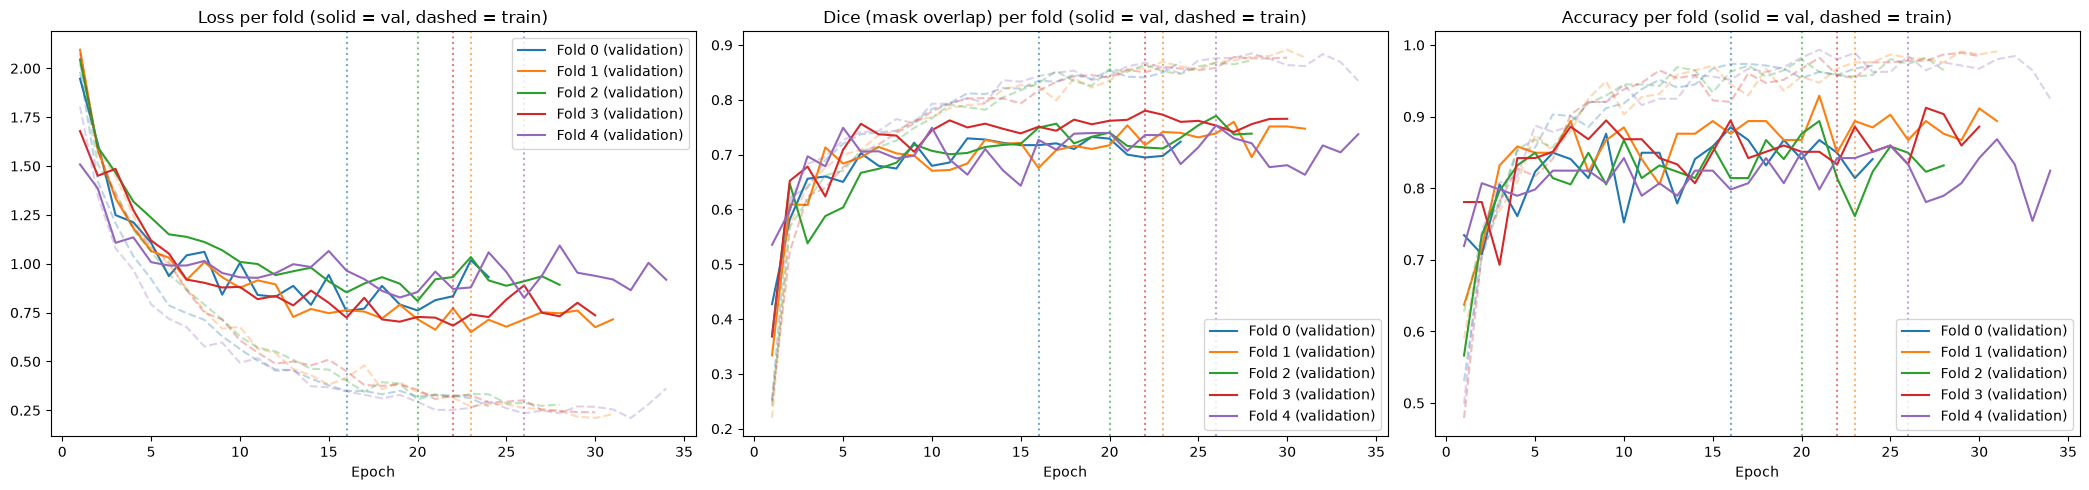

In [103]:
plots = [('loss', 'Loss'), ('dice', 'Dice (mask overlap)')] + ([('acc', 'Accuracy')] if MULTI_TASK else [])
fig, axes = plt.subplots(1, len(plots), figsize=(7 * len(plots), 5))
for fold, fold_history in history.groupby('fold'):
    for ax, (metric, _) in zip(axes, plots):
        line, = ax.plot(fold_history['epoch'], fold_history[f'val_{metric}'], label=f'Fold {fold} (validation)')
        ax.plot(fold_history['epoch'], fold_history[f'train_{metric}'], color=line.get_color(), alpha=0.3, linestyle='--')
        ax.axvline(best_epochs[fold], color=line.get_color(), linestyle=':', alpha=0.6)
for ax, (_, title) in zip(axes, plots):
    ax.set_xlabel('Epoch')
    ax.set_title(f'{title} per fold (solid = val, dashed = train)')
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Predictions: out-of-fold and ensemble (v3)

| Images | Predicted by | Used for |
| ------ | ------------ | -------- |
| **Cross-validation images** (567) | The fold model that **didn't** train on that image (*out-of-fold*) | Tuning the malignant threshold |
| **Test images** (102) | All 5 fold models; their **lesion probability maps and class probabilities are averaged** (*ensemble*) | The final test results |

The averaged probability map then goes through the v2 steps: smooth enlargement to the original size, threshold, cleanup.

In [104]:
fold_models = []
for fold in range(N_FOLDS):
    net = build_model(pretrained=False)
    net.load_state_dict(torch.load(OUTPUT_DIR / f'model_fold{fold}.pt', map_location=device))
    net.eval()
    fold_models.append(net)


def predict_set(model, frame, keep_masks=True):
    """Lesion probability maps (N, size, size) (or None) and class probabilities (N, 3) (or None) for a frame."""
    mask_probs, class_probs = [], []
    with torch.no_grad():
        for images, _, _ in make_loader(frame):
            mask_logits, class_logits = forward(model, images.to(device))
            if keep_masks:
                mask_probs.append(torch.sigmoid(mask_logits)[:, 0].cpu())          # lesion probability per pixel
            if MULTI_TASK:
                class_probs.append(torch.softmax(class_logits, dim=1).cpu())   # [P(normal), P(benign), P(malignant)]
    return (torch.cat(mask_probs).numpy() if keep_masks else None,
            torch.cat(class_probs).numpy() if MULTI_TASK else None)


def decide(probs, malignant_threshold=None):
    """Class numbers from probabilities. No threshold: most likely class. With a threshold (v2):
    malignant if P(malignant) >= threshold, otherwise the more likely of normal / benign."""
    if malignant_threshold is None:
        return probs.argmax(axis=1)
    return np.where(probs[:, 2] >= malignant_threshold, 2, probs[:, :2].argmax(axis=1))


# Out-of-fold class probabilities (masks aren't needed for tuning the threshold)
oof_probs = np.zeros((len(pool_df), len(CLASSES))) if MULTI_TASK else None
if MULTI_TASK:
    for fold, net in enumerate(fold_models):
        in_fold = (pool_df['fold'] == fold).values
        oof_probs[in_fold] = predict_set(net, pool_df[in_fold], keep_masks=False)[1]

# Test: every fold model. Keep each model's class probabilities and Dice (for single vs ensemble),
# and add up the probability maps for the ensemble.
truths = [np.array(load_mask(row['mask_paths'])) > 127 for _, row in test_df.iterrows()]
mask_sum, fold_class_probs, fold_dice, fold_area = None, [], [], []
for fold, net in enumerate(fold_models):
    fold_mask_probs, class_probs_k = predict_set(net, test_df)
    mask_sum = fold_mask_probs if mask_sum is None else mask_sum + fold_mask_probs
    fold_class_probs.append(class_probs_k)
    fold_masks = [final_mask(fold_mask_probs[i], row['width'], row['height']) for i, row in test_df.iterrows()]
    fold_dice.append([dice_score(m, t) for m, t in zip(fold_masks, truths)])
    fold_area.append([int(m.sum()) for m in fold_masks])
    print(f'Predicted the test set with fold model {fold}')

mask_probs = mask_sum / N_FOLDS                                                  # ensemble probability maps
class_probs = np.mean(fold_class_probs, axis=0) if MULTI_TASK else None          # ensemble class probabilities

Predicted the test set with fold model 0
Predicted the test set with fold model 1
Predicted the test set with fold model 2
Predicted the test set with fold model 3
Predicted the test set with fold model 4


### Tune the malignant threshold on the out-of-fold predictions

The **highest** threshold that still catches `TARGET_MALIGNANT_RECALL` of the **567 out-of-fold** cancers (same method as `02_model_classifier`).

Malignant threshold: 0.22  (out-of-fold recall 0.900, precision 0.801, 170 cancers)


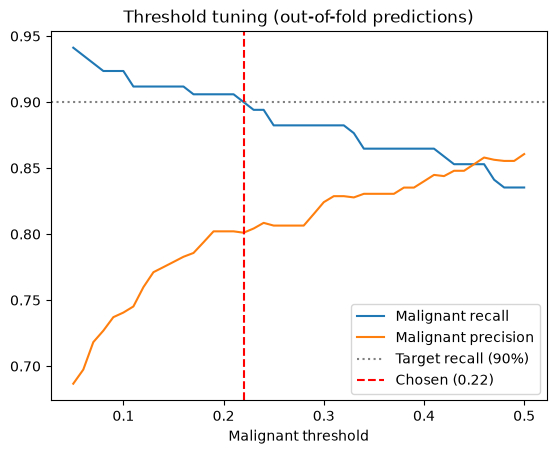

In [105]:
MALIGNANT_THRESHOLD = None
if MULTI_TASK:
    y_oof_true = pool_df['target'].values
    oof_is_malignant = y_oof_true == 2
    rows = []
    for threshold in np.round(np.arange(0.05, 0.51, 0.01), 2):
        pred = decide(oof_probs, threshold)
        caught = ((pred == 2) & oof_is_malignant).sum()
        rows.append({'threshold': threshold, 'recall': caught / oof_is_malignant.sum(),
                     'precision': caught / max((pred == 2).sum(), 1)})
    tuning = pd.DataFrame(rows)
    meets_target = tuning[tuning['recall'] >= TARGET_MALIGNANT_RECALL]
    if len(meets_target):
        MALIGNANT_THRESHOLD = float(meets_target['threshold'].max())
    else:
        MALIGNANT_THRESHOLD = float(tuning.loc[tuning['recall'].idxmax(), 'threshold'])
        print(f'Target recall {TARGET_MALIGNANT_RECALL:.0%} not reached: using the threshold with the best recall')
    chosen = tuning[tuning['threshold'] == MALIGNANT_THRESHOLD].iloc[0]
    print(f"Malignant threshold: {MALIGNANT_THRESHOLD:.2f}  (out-of-fold recall {chosen['recall']:.3f}, "
          f"precision {chosen['precision']:.3f}, {oof_is_malignant.sum()} cancers)")

    plt.plot(tuning['threshold'], tuning['recall'], label='Malignant recall')
    plt.plot(tuning['threshold'], tuning['precision'], label='Malignant precision')
    plt.axhline(TARGET_MALIGNANT_RECALL, color='grey', linestyle=':', label=f'Target recall ({TARGET_MALIGNANT_RECALL:.0%})')
    plt.axvline(MALIGNANT_THRESHOLD, color='red', linestyle='--', label=f'Chosen ({MALIGNANT_THRESHOLD:.2f})')
    plt.xlabel('Malignant threshold')
    plt.title('Threshold tuning (out-of-fold predictions)')
    plt.legend()
    plt.savefig(OUTPUT_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
    plt.show()

    oof = pool_df[['image_path', 'label', 'fold']].copy()
    for k, class_name in enumerate(CLASSES):
        oof[f'prob_{class_name}'] = oof_probs[:, k].round(4)
    oof['predicted'] = [CLASSES[k] for k in decide(oof_probs, MALIGNANT_THRESHOLD)]
    oof.to_csv(OUTPUT_DIR / 'oof_predictions.csv', index=False)

## 8. Test results

Each ensemble probability map is turned into a final mask (smooth enlargement, threshold, cleanup), compared with the true mask (Dice, IoU) and saved to `masks/` for `04_measure`.

In [106]:
y_pred = decide(class_probs, MALIGNANT_THRESHOLD) if MULTI_TASK else None     # v3: ensemble + tuned threshold

rows = []
for i, row in test_df.iterrows():
    pred = final_mask(mask_probs[i], row['width'], row['height'])
    truth = truths[i]

    mask_path = MASK_DIR / row['image_path']                     # e.g. masks/benign/benign (12).png
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(pred.astype(np.uint8) * 255).save(mask_path)

    rows.append({
        'image_path': row['image_path'], 'label': row['label'], 'target': row['target'],
        'has_markers': row['has_markers'], 'pred_mask_path': str(mask_path.relative_to(OUTPUT_DIR)),
        'dice': dice_score(pred, truth), 'iou': iou_score(pred, truth),
        'true_area_px': int(truth.sum()), 'pred_area_px': int(pred.sum()),
    })

results = pd.DataFrame(rows)
if MULTI_TASK:
    for k, class_name in enumerate(CLASSES):
        results[f'prob_{class_name}'] = class_probs[:, k]
    results['predicted'] = [CLASSES[k] for k in y_pred]
    results['correct'] = results['predicted'] == results['label']

results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
print(f'Saved {len(results)} predicted masks to {MASK_DIR}')
if MULTI_TASK:
    print(f'\nv3: ensemble of {N_FOLDS} models, malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}')
    print(classification_report(results['target'], y_pred, target_names=CLASSES, digits=3))

Saved 102 predicted masks to outputs/unet_multitask/masks

v3: ensemble of 5 models, malignant if P(malignant) >= 0.22
              precision    recall  f1-score   support

      normal      0.789     0.882     0.833        17
      benign      0.962     0.895     0.927        57
   malignant      0.900     0.964     0.931        28

    accuracy                          0.912       102
   macro avg      0.884     0.914     0.897       102
weighted avg      0.916     0.912     0.913       102



### v1, v2 and v3 on the same test images

v1 and v2 are rescored from the archived per-image results (`outputs/archive/v2_postprocessing/`), using only the 102 current test images.

| Version | Masks | Class |
| ------- | ----- | ----- |
| v1 | One model, 256 px, raw masks | Most likely class |
| v2 | Same model, smoothed and cleaned masks | Threshold tuned on validation (came out at 0.50) |
| v3 | 5 models at 384 px, averaged, smoothed and cleaned | Threshold tuned on the out-of-fold predictions |

- **Dice and IoU** are averaged over **tumour images only**.
- **95% ranges:** bootstrap with 1,000 resampled test sets; every version uses the same 1,000 draws.

In [107]:
def compute_metrics(frame, s=''):
    """All test scores from a per-image results frame. s = '_v1' reads the v1 columns of the archived v2 file."""
    label = frame['label'].values
    is_tumour_img = label != 'normal'
    dice, iou = frame['dice' + s].values, frame['iou' + s].values
    has_lesion = frame['pred_area_px' + s].values >= MIN_LESION_PIXELS
    metrics = {
        'dice_tumour_images': float(dice[is_tumour_img].mean()),
        'iou_tumour_images': float(iou[is_tumour_img].mean()),
        'dice_benign': float(dice[label == 'benign'].mean()),
        'dice_malignant': float(dice[label == 'malignant'].mean()),
        'normal_images_with_false_lesion': float(has_lesion[~is_tumour_img].mean()),
        'tumour_images_with_no_lesion_found': float((~has_lesion[is_tumour_img]).mean()),
    }
    if MULTI_TASK:
        y_true = frame['target'].values
        y_pred = frame['predicted' + s].map(CLASSES.index).values
        probs = frame[[f'prob_{c}' for c in CLASSES]].values
        is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]
        is_malignant, p_malignant = y_true == 2, probs[:, 2]
        pred_tumour, pred_malignant = p_tumour >= 0.5, y_pred == 2
        metrics.update({
            'accuracy': float((y_pred == y_true).mean()),
            'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / max(is_tumour.sum(), 1)),
            'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / max((~is_tumour).sum(), 1)),
            'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
            'malignant_recall': float((pred_malignant & is_malignant).sum() / max(is_malignant.sum(), 1)),
            'malignant_precision': float((pred_malignant & is_malignant).sum() / max(pred_malignant.sum(), 1)),
            'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
        })
    return metrics


def confidence_range(frame, s='', n=N_BOOTSTRAP):
    """95% range of every score: re-draw the test set n times (same size, with replacement) and re-score it."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = [compute_metrics(frame.iloc[rng.integers(0, len(frame), size=len(frame))], s) for _ in range(n)]
    scores = pd.DataFrame(scores)
    return scores.quantile(0.025), scores.quantile(0.975)


# v1 and v2 from the archived per-image results, same images in the same order as the current test set
archived = (pd.read_csv(ARCHIVE_DIR / 'v2_postprocessing' / OUTPUT_DIR.name / 'test_predictions.csv')
            .set_index('image_path').loc[results['image_path']].reset_index())
versions = {'v1': (archived, '_v1'), 'v2': (archived, ''), 'v3': (results, '')}

table = {}
for name, (frame, s) in versions.items():
    scores = compute_metrics(frame, s)
    low, high = confidence_range(frame, s)
    table[name] = pd.Series(scores)
    table[f'{name} 95% range'] = pd.Series({k: f'{low[k]:.3f} - {high[k]:.3f}' for k in scores})
    if name == 'v3':
        metrics = dict(scores)
        metrics['confidence_95'] = {k: [round(float(low[k]), 4), round(float(high[k]), 4)] for k in scores}

comparison = pd.DataFrame(table)
comparison.to_csv(OUTPUT_DIR / 'metrics_by_version.csv')
(OUTPUT_DIR / 'metrics_v1_vs_v2.csv').unlink(missing_ok=True)     # v3: replaced by metrics_by_version.csv
comparison.round(3)

,v1,v1 95% range,v2,v2 95% range,v3,v3 95% range
dice_tumour_images,0.766,0.700 - 0.824,0.768,0.702 - 0.825,0.793,0.732 - 0.851
iou_tumour_images,0.686,0.622 - 0.743,0.690,0.625 - 0.747,0.725,0.663 - 0.782
dice_benign,0.779,0.704 - 0.853,0.781,0.705 - 0.856,0.805,0.726 - 0.883
dice_malignant,0.738,0.636 - 0.827,0.740,0.638 - 0.830,0.770,0.667 - 0.853
normal_images_with_false_lesion,0.176,0.000 - 0.400,0.176,0.000 - 0.400,0.176,0.000 - 0.369
tumour_images_with_no_lesion_found,0.035,0.000 - 0.080,0.047,0.011 - 0.096,0.082,0.033 - 0.144
accuracy,0.863,0.784 - 0.931,0.863,0.784 - 0.931,0.912,0.853 - 0.961
tumour_sensitivity,0.953,0.905 - 0.989,0.953,0.905 - 0.989,0.941,0.884 - 0.987
tumour_specificity,0.824,0.600 - 1.000,0.824,0.600 - 1.000,0.882,0.706 - 1.000
tumour_roc_auc,0.983,0.957 - 0.997,0.983,0.957 - 0.997,0.985,0.962 - 0.998


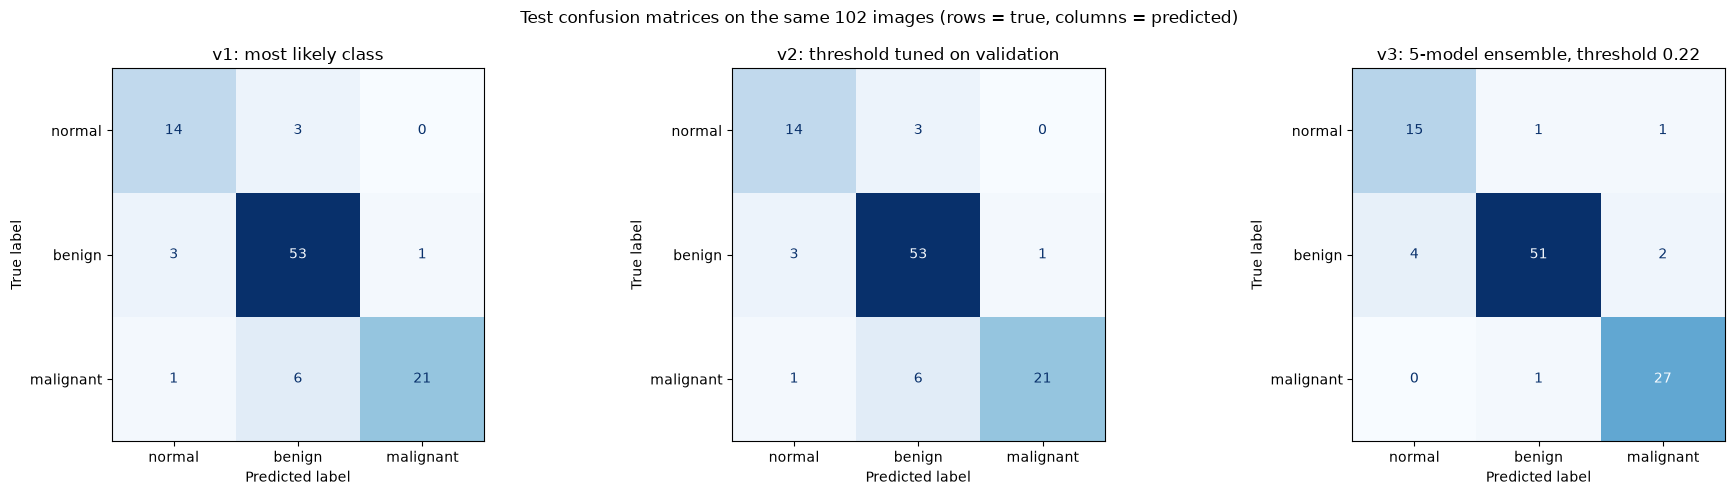

In [108]:
if MULTI_TASK:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    y_true = results['target'].values
    for ax, (title, pred) in zip(axes, [
        ('v1: most likely class', archived['predicted_v1'].map(CLASSES.index).values),
        (f'v2: threshold tuned on validation', archived['predicted'].map(CLASSES.index).values),
        (f'v3: 5-model ensemble, threshold {MALIGNANT_THRESHOLD:.2f}', y_pred),
    ]):
        ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=CLASSES).plot(cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(title)
    plt.suptitle(f'Test confusion matrices on the same {len(y_true)} images (rows = true, columns = predicted)')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
    plt.show()

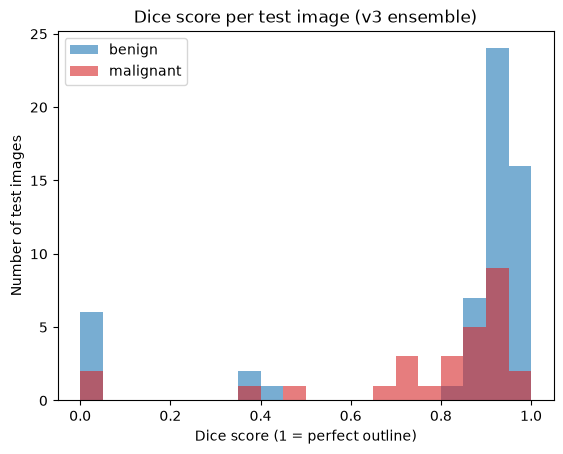

In [109]:
# Dice score of every tumour image, by class (v3)
for class_name, color in [('benign', 'tab:blue'), ('malignant', 'tab:red')]:
    plt.hist(results.loc[results['label'] == class_name, 'dice'], bins=20, range=(0, 1),
             alpha=0.6, color=color, label=class_name)
plt.xlabel('Dice score (1 = perfect outline)')
plt.ylabel('Number of test images')
plt.title('Dice score per test image (v3 ensemble)')
plt.legend()
plt.savefig(OUTPUT_DIR / 'dice_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

### Single models vs the ensemble

Each fold model on its own (same smoothing, cleanup and threshold) compared with their average.

In [110]:
rows = {}
for fold in range(N_FOLDS):
    single = results[['image_path', 'label', 'target']].copy()
    single['dice'], single['iou'] = fold_dice[fold], fold_dice[fold]          # IoU isn't needed for this table
    single['pred_area_px'] = fold_area[fold]
    if MULTI_TASK:
        for k, class_name in enumerate(CLASSES):
            single[f'prob_{class_name}'] = fold_class_probs[fold][:, k]
        single['predicted'] = [CLASSES[k] for k in decide(fold_class_probs[fold], MALIGNANT_THRESHOLD)]
    rows[f'model {fold}'] = compute_metrics(single)

single_table = pd.DataFrame(rows).T.drop(columns='iou_tumour_images')
single_table.loc['average of single models'] = single_table.mean()
single_table.loc['ensemble (v3)'] = pd.Series({k: v for k, v in metrics.items() if k in single_table.columns})
single_table.to_csv(OUTPUT_DIR / 'single_vs_ensemble.csv')
single_table.round(3)

,dice_tumour_images,dice_benign,dice_malignant,normal_images_with_false_lesion,tumour_images_with_no_lesion_found,accuracy,tumour_sensitivity,tumour_specificity,tumour_roc_auc,malignant_recall,malignant_precision,malignant_roc_auc
model 0,0.763,0.778,0.732,0.471,0.012,0.824,1.000,0.647,0.983,0.857,0.706,0.945
model 1,0.781,0.796,0.752,0.294,0.047,0.873,0.929,0.882,0.975,0.786,0.917,0.944
model 2,0.767,0.771,0.760,0.176,0.035,0.912,0.965,0.882,0.979,0.929,0.839,0.981
model 3,0.755,0.769,0.726,0.294,0.094,0.804,0.894,0.765,0.914,0.750,0.875,0.942
model 4,0.771,0.765,0.783,0.176,0.082,0.912,0.929,0.941,0.975,0.964,0.900,0.980
average of single models,0.767,0.776,0.750,0.282,0.054,0.865,0.944,0.824,0.965,0.857,0.847,0.959
ensemble (v3),0.793,0.805,0.770,0.176,0.082,0.912,0.941,0.882,0.985,0.964,0.900,0.981


### Shortcut check: images with vs without markers

If results are much better on images with markers, the model may be using the markers instead of the tissue.

In [111]:
tumour = results['label'] != 'normal'
marker_check = results[tumour].groupby('has_markers')['dice'].agg(dice='mean', images='count')
metrics['dice_with_markers'] = float(marker_check['dice'].get(True, float('nan')))
metrics['dice_without_markers'] = float(marker_check['dice'].get(False, float('nan')))
if MULTI_TASK:
    accuracy_check = results.groupby('has_markers')['correct'].mean()
    metrics['accuracy_with_markers'] = float(accuracy_check.get(True, float('nan')))
    metrics['accuracy_without_markers'] = float(accuracy_check.get(False, float('nan')))

# The settings these results were produced with
metrics.update({'malignant_threshold': MALIGNANT_THRESHOLD, 'smooth_masks': SMOOTH_MASKS, 'clean_masks': CLEAN_MASKS,
                'image_size': IMAGE_SIZE, 'n_models': N_FOLDS, 'test_images': int(len(results))})
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))     # save all test results (v3)
marker_check.round(3)

,dice,images
has_markers,,
False,0.873,29
True,0.752,56


## 9. See the predictions

**Green** = true lesion outline, **red** = predicted outline (v3 ensemble).

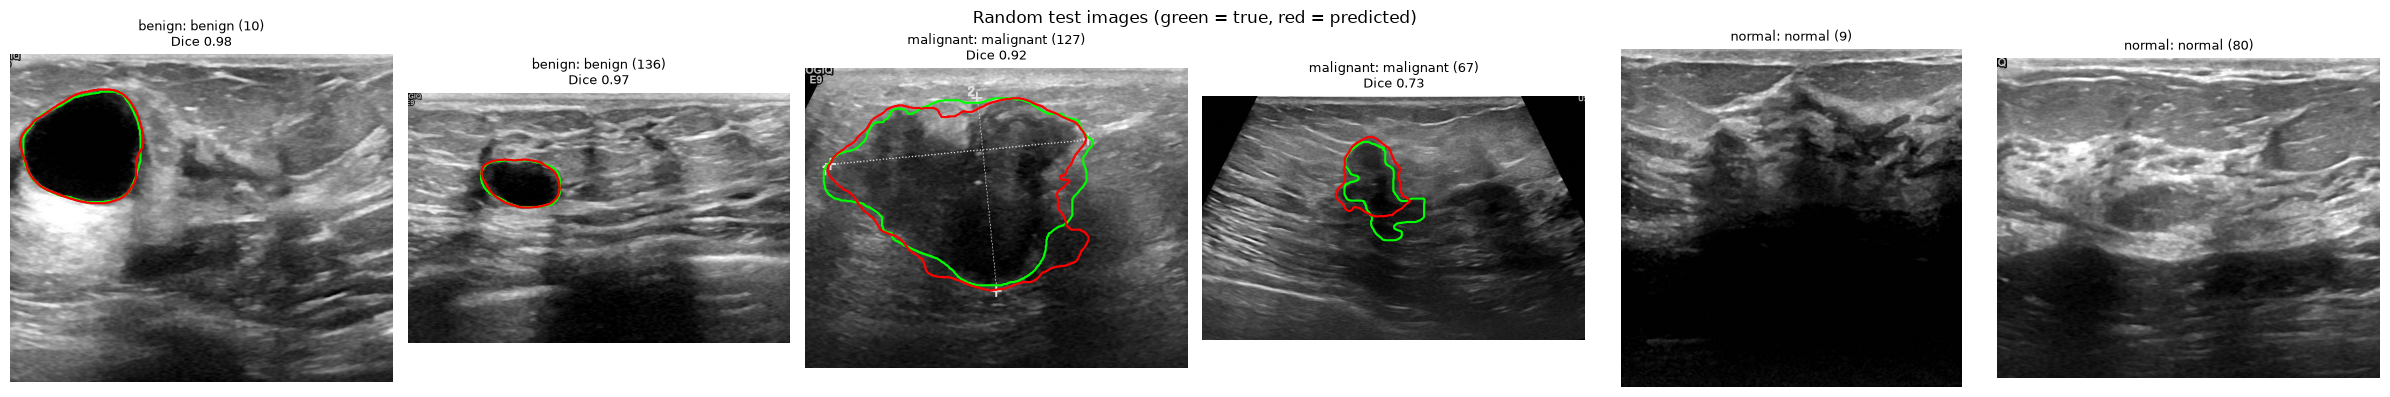

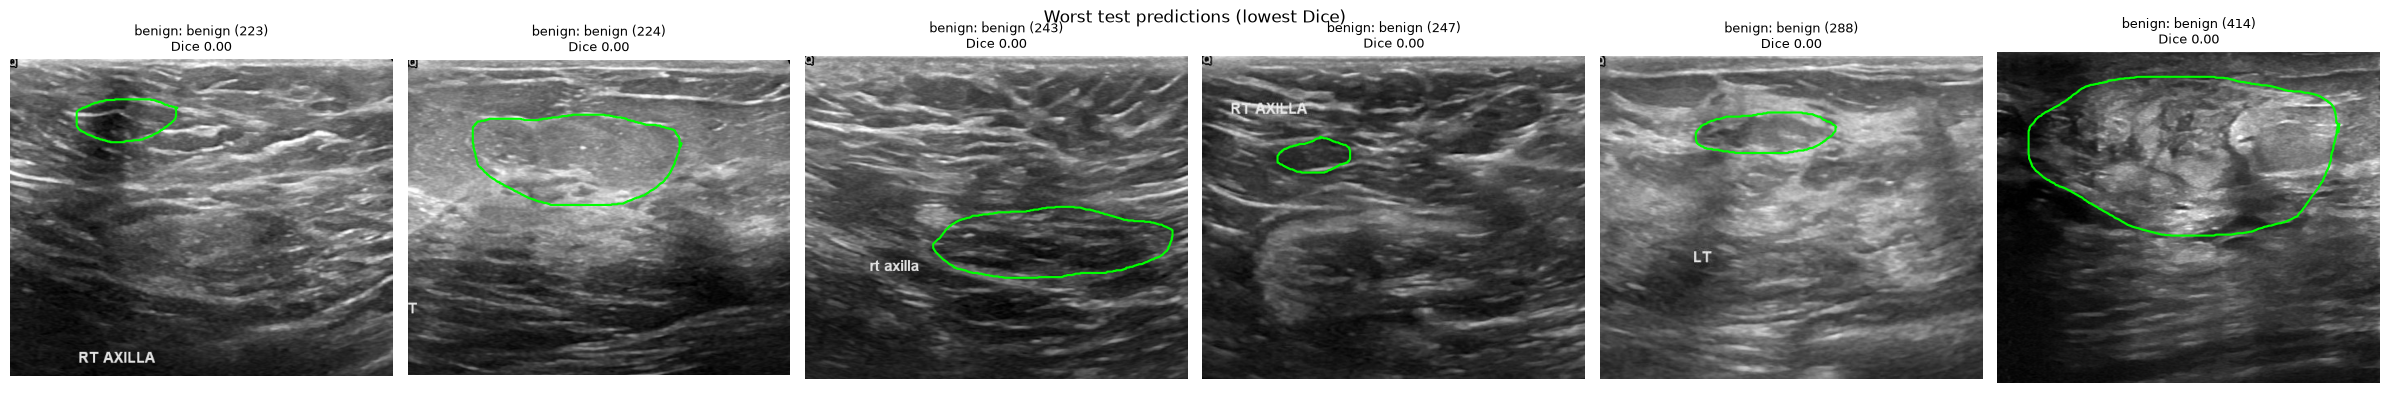

In [112]:
def show_predictions(rows, title, file_name):
    """Show test images with the true (green) and predicted (red) outlines, and save the figure."""
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        image = Image.open(DATA_DIR / row.image_path).convert('L')
        truth = np.array(load_mask(test_df.loc[test_df['image_path'] == row.image_path, 'mask_paths'].iloc[0])) > 127
        pred = np.array(Image.open(OUTPUT_DIR / row.pred_mask_path)) > 127

        ax.imshow(image, cmap='gray')
        if truth.any():
            ax.contour(truth, levels=[0.5], colors='lime', linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)

        name = f'{row.label}: {Path(row.image_path).stem}'
        ax.set_title(f'{name}\nDice {row.dice:.2f}' if row.label != 'normal' else name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()


examples = results.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class
show_predictions(examples, 'Random test images (green = true, red = predicted)', 'prediction_examples.png')

worst = results[tumour].nsmallest(6, 'dice')                                             # hardest cases
show_predictions(worst, 'Worst test predictions (lowest Dice)', 'worst_predictions.png')

## 10. Save the config

The app needs to rebuild exactly the same models, preprocess uploaded images the same way and use the same thresholds. Everything it needs is stored here.

In [113]:
config = {
    'model_name': f"U-Net{' (multi-task)' if MULTI_TASK else ''}, {N_FOLDS}-model ensemble",
    'architecture': 'Unet',
    'encoder': ENCODER,
    'multi_task': MULTI_TASK,
    'model_files': [f'model_fold{fold}.pt' for fold in range(N_FOLDS)],   # v3: the app averages these models
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'mask_threshold': MASK_THRESHOLD,
    'min_lesion_pixels': MIN_LESION_PIXELS,
    'smooth_masks': SMOOTH_MASKS,
    'clean_masks': CLEAN_MASKS,
    'min_region_pct': MIN_REGION_PCT,
    'malignant_threshold': MALIGNANT_THRESHOLD,
    'threshold_tuned_on': f'out-of-fold predictions ({len(pool_df)} images, {N_FOLDS}-fold cross-validation)',
    'decision_rule': 'average the models; malignant if P(malignant) >= malignant_threshold, else the more likely '
                     'of normal / benign; mask = averaged probability map, enlarged smoothly, thresholded, cleaned',
    'classification_dropout': 0.2,
    'class_loss_weight': CLASS_LOSS_WEIGHT,
    'best_epochs': [int(e) for e in best_epochs],
    'epochs_trained': history.groupby('fold').size().astype(int).tolist(),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'images': {'cross_validation': len(pool_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M') if TRAIN else previous_config['trained_on'],
    'evaluated_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    size = sum(f.stat().st_size for f in path.rglob('*')) if path.is_dir() else path.stat().st_size
    print(f'  {path.name:26s} {size / 1024:10.1f} KB')

Saved files:
  config.json                       1.4 KB
  confusion_matrix.png             60.6 KB
  dice_distribution.png            22.7 KB
  history.csv                      17.0 KB
  lesion_matches.csv                9.4 KB
  masks                           110.3 KB
  measurement_metrics.json          0.5 KB
  measurements.csv                 16.6 KB
  metrics.json                      1.7 KB
  metrics_by_version.csv            1.5 KB
  model_fold0.pt                95628.6 KB
  model_fold1.pt                95628.6 KB
  model_fold2.pt                95628.6 KB
  model_fold3.pt                95628.6 KB
  model_fold4.pt                95628.6 KB
  oof_predictions.csv              34.5 KB
  overlays                      17609.6 KB
  prediction_examples.png         743.5 KB
  single_vs_ensemble.csv            1.8 KB
  size_comparison.png              67.0 KB
  test_predictions.csv             16.1 KB
  threshold_tuning.png             39.4 KB
  training_curves.png             342.0 K

## 11. Check: reload and predict, the way the app will

This rebuilds the 5 models from the saved files alone and predicts one test image. Its mask should match the one saved in `masks/` (Dice close to 1).

In [114]:
def load_unet(folder):
    """Rebuild the trained fold models from config.json and model_fold*.pt."""
    config = json.loads((folder / 'config.json').read_text())
    head = {'classes': len(config['classes']), 'dropout': config['classification_dropout']} if config['multi_task'] else None
    nets = []
    for file_name in config['model_files']:
        net = smp.Unet(encoder_name=config['encoder'], encoder_weights=None, in_channels=3, classes=1, aux_params=head)
        net.load_state_dict(torch.load(folder / file_name, map_location='cpu'))
        net.eval()
        nets.append(net)
    return nets, config


def predict(nets, config, image):
    """For one PIL image: lesion mask at the original size, plus class probabilities and predicted class if multi-task.
    The models' probability maps and class probabilities are averaged."""
    size = config['image_size']
    width, height = image.size
    padded = ImageOps.pad(image.convert('L'), (size, size), method=Image.BICUBIC, color=0)
    x = torch.from_numpy(np.array(padded)).float().div(255).unsqueeze(0).repeat(3, 1, 1)
    x = (x - torch.tensor(config['normalize_mean']).view(3, 1, 1)) / torch.tensor(config['normalize_std']).view(3, 1, 1)

    lesion_maps, class_scores = [], []
    with torch.no_grad():
        for net in nets:
            output = net(x.unsqueeze(0))
            mask_logits, class_logits = output if config['multi_task'] else (output, None)
            lesion_maps.append(torch.sigmoid(mask_logits)[0, 0].numpy())
            if class_logits is not None:
                class_scores.append(torch.softmax(class_logits, dim=1)[0].numpy())
    lesion_probs = np.mean(lesion_maps, axis=0)

    if config.get('smooth_masks'):
        mask = unpad_probs(lesion_probs, width, height, size) > config['mask_threshold']
    else:
        mask = unpad_mask(lesion_probs > config['mask_threshold'], width, height, size)
    if config.get('clean_masks'):
        mask = clean_mask(mask, config['min_region_pct'], config['min_lesion_pixels'])

    probabilities, predicted = None, None
    if class_scores:
        p = np.mean(class_scores, axis=0)
        index = 2 if p[2] >= config['malignant_threshold'] else int(p[:2].argmax())
        predicted = config['classes'][index]
        probabilities = dict(zip(config['classes'], p.round(4).tolist()))
    return mask, probabilities, predicted


nets, saved_config = load_unet(OUTPUT_DIR)
sample = results[tumour].iloc[0]
mask, probabilities, predicted = predict(nets, saved_config, Image.open(DATA_DIR / sample['image_path']))
saved_mask = np.array(Image.open(OUTPUT_DIR / sample['pred_mask_path'])) > 127

print('Image:          ', sample['image_path'])
print('True label:     ', sample['label'])
print('Probabilities:  ', probabilities)
print('Predicted:      ', predicted)
print(f'Lesion pixels:   {mask.sum()}')
print(f'Match with saved mask (Dice): {dice_score(mask, saved_mask):.3f}  (should be close to 1)')

Image:           benign/benign (10).png
True label:      benign
Probabilities:   {'normal': 9.999999747378752e-05, 'benign': 0.9986000061035156, 'malignant': 0.0013000000035390258}
Predicted:       benign
Lesion pixels:   33930
Match with saved mask (Dice): 1.000  (should be close to 1)


## 12. Key findings (v3)

*Fill in after running the notebook.*

- **Fold models (best epochs, val Dice):**
- **Malignant threshold (out-of-fold):**
- **v1 → v2 → v3: Dice, false lesions on normal scans, malignant recall:**
- **Ensemble vs single models:**
- **Next:** run `04_measure` to see whether 384 px fixed the too-smooth malignant outlines (shape agreement on irregular lesions)